# 정규분포·Z점수·중심극한정리 정답지

표준화는 단위 조정이며 정규분포로 만드는 작업이 아닙니다. 중심극한정리는 원자료가 아니라 표본평균의 분포에 관한 정리입니다.

**학습 목표:** 경험적 규칙, Z점수와 백분위, 정규성 진단과 p값, 중심극한정리

공식 → 직접 구현 또는 계산 → 라이브러리 대조 → 해석 순서로 학습합니다.

## 실행 준비

Python 3.11 이상, NumPy·pandas·SciPy·Matplotlib이 필요합니다. 없는 경우 별도 셀에서 `%pip install numpy pandas scipy matplotlib`을 한 번 실행하세요. 새 커널에서 위에서 아래로 실행합니다. 외부 데이터 다운로드는 없습니다. 그래프는 폰트 호환을 위해 영문 제목을 쓰고 해석은 한국어로 제공합니다.

**표기:** 기본 기술 분산은 ddof=0, 모집단 분산 추정·평균 추론은 ddof=1을 명시합니다. 난수는 seed=42(문제에 지정 시 해당 seed)입니다.

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
# 외부 파일 없이 재현 가능한 학습용 가상 자료
x = np.array([12, 15, 14, 10, 18, 20, 22, 25, 30, 28], dtype=float)
y = np.array([2, 4, 6, 8, 10, 12, 14, 40], dtype=float)
plt.rcParams['axes.unicode_minus'] = False


## 문제 1. 경험적 규칙

키가 정규분포 N(165, 6²)일 때 1σ,2σ,3σ 구간과 153 ~ 177cm 확률을 구하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [2]:
# 문제 1 풀이
print([(165-k*6,165+k*6) for k in (1,2,3)])
p=stats.norm.cdf(177,loc=165,scale=6)-stats.norm.cdf(153,loc=165,scale=6)
print(p);assert np.isclose(p,.9544997361)

[(159, 171), (153, 177), (147, 183)]
0.9544997361036416


**결과 해석 / 근거 / 새로 알게 된 점:**

159 ~ 171,153 ~ 177,147 ~ 183cm입니다. 가운데 두 표준편차 구간 확률은 약 95.45%이며 관측 표본이 반드시 그 비율을 정확히 만족하는 것은 아닙니다.

## 문제 2. Z점수와 백분위

평균 165, 표준편차 6인 정규모형에서 키 174의 Z점수와 백분위를 구하고, y를 ddof=0으로 표준화해 정규분포가 되었는지 설명하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

In [3]:
# 문제 2 풀이
z=(174-165)/6
print(z,stats.norm.cdf(z)*100)
zy=(y-y.mean())/y.std(ddof=0)
print(zy,zy.mean(),zy.std(ddof=0))
assert np.isclose(z,1.5)

1.5 93.3192798731142
[-0.89087081 -0.71269665 -0.53452248 -0.35634832 -0.17817416  0.
  0.17817416  2.49443826] 0.0 0.9999999999999999


**결과 해석 / 근거 / 새로 알게 된 점:**

z=1.5, 약 93.32백분위입니다. y 표준화는 평균 0, 표준편차 1을 만들지만 비대칭과 이상치 구조를 그대로 유지합니다.

## 문제 3. 정규성 진단과 p값

y에 Shapiro 검정과 Q-Q plot을 적용하고 alpha=.05에서 판단하세요. 독립 관측이 필요함도 적으세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

ShapiroResult(statistic=np.float64(0.7404027706734726), pvalue=np.float64(0.006393729455486044))
기각


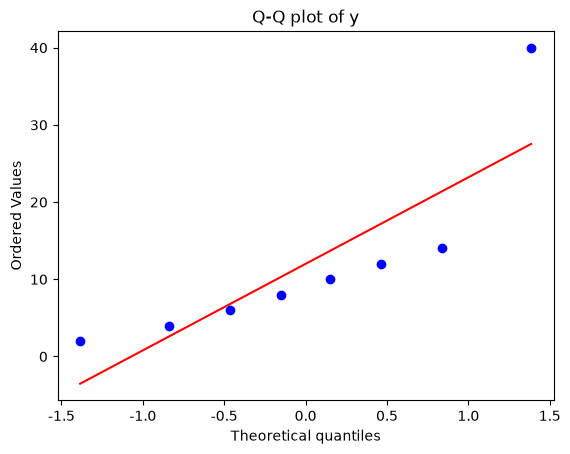

In [4]:
# 문제 3 풀이
r=stats.shapiro(y);print(r)
print('기각' if r.pvalue<.05 else '기각하지 못함')
stats.probplot(y,dist='norm',plot=plt);plt.title('Q-Q plot of y');plt.show()

**결과 해석 / 근거 / 새로 알게 된 점:**

큰 값 40 때문에 정규모형과 어긋나는 꼬리가 보입니다. 판단은 출력된 p값과 그래프에 근거합니다. 작은 표본에서는 결과가 불안정하며 독립성이 없는 자료는 이 검정만으로 분석 가정을 보장하지 못합니다.

## 문제 4. 중심극한정리

seed=123으로 지수분포(scale=3)에서 n=5와 n=100의 표본평균을 각각 3000개 만들고 평균·경험적 표준오차·이론 표준오차를 비교하세요.

**점검 기준:** 요구한 계산값·그래프와 사용한 가정, 단위를 함께 기록하세요.

5 2.9563350971112388 1.3185255168636045 1.3416407864998738
100 3.0007067324995926 0.30376949510038354 0.3


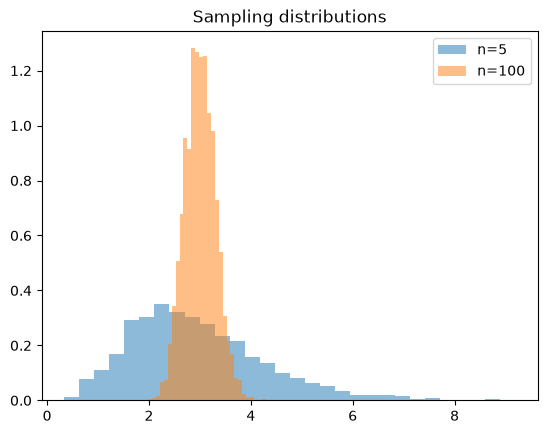

In [5]:
# 문제 4 풀이
g=np.random.default_rng(123)
for n in (5,100):
    m=g.exponential(3,size=(3000,n)).mean(axis=1)
    print(n,m.mean(),m.std(ddof=1),3/np.sqrt(n))
    plt.hist(m,bins=30,density=True,alpha=.5,label=f'n={n}')
plt.legend();plt.title('Sampling distributions');plt.show()

**결과 해석 / 근거 / 새로 알게 된 점:**

표본평균 중심은 약 3에 머물고 n=100에서는 퍼짐이 줄어듭니다. 이론 표준오차는 약 1.342와 0.3입니다. 원래 지수분포 자체가 정규분포로 바뀐 것은 아닙니다.

## 복습 순서

1. 관측 대상과 통계량의 의미를 말로 설명합니다.
2. 분모·단위·독립성·분포 가정을 확인합니다.
3. 직접 계산과 라이브러리 결과를 비교합니다.
4. 코드 결과와 실제로 주장할 수 있는 범위를 구분합니다.

**학습 이동:** `Statistics_2_normal_clt.ipynb` → `Statistics_2_normal_clt_Practice.ipynb` → `Statistics_2_normal_clt_Answer.ipynb`.